# Ejercicio Gradiente multidimensional

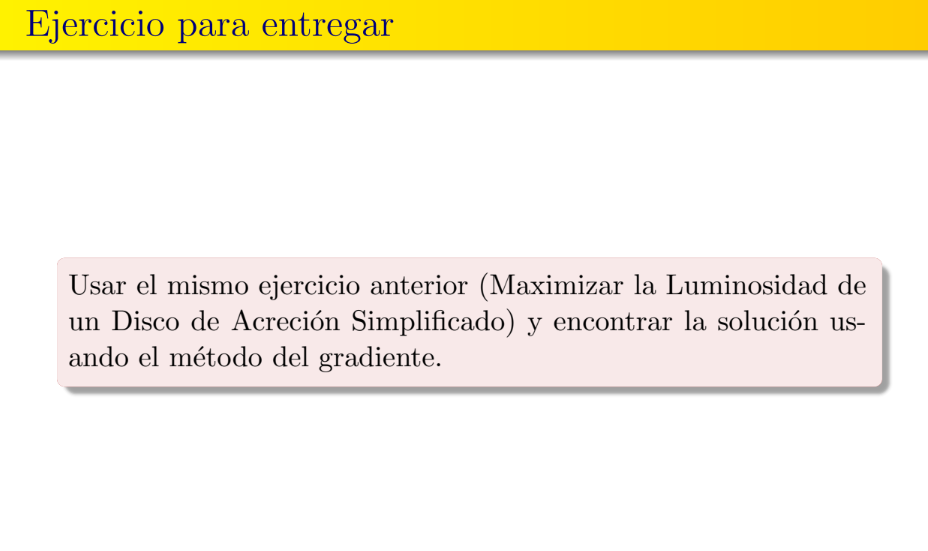

## funcion
$$L = f(r,\theta) = r^2 \sin \theta (1 + \cos \theta) e^{-r/r_0}$$

## Primera derivada
$L(r, \theta) = g(r) \cdot h(\theta)$

$g(r) = r^2 e^{-r}$

$h(\theta) = \sin(\theta) (1 + \cos(\theta))$

Se deriva cada funcion

$g'(r) = (2r)(e^{-r}) + (r^2)(-e^{-r})$ 

$g'(r) = e^{-r}(2r - r^2)$

Obtenemos la primera componente:
$\frac{\partial L}{\partial r} = e^{-r}(2r - r^2) \sin(\theta) (1 + \cos(\theta))$

para $\frac{\partial L}{\partial \theta}$

$\frac{\partial L}{\partial \theta} = r^2 e^{-r} (\cos(\theta) + \cos^2(\theta) - \sin^2(\theta))$

Por lo tanto nuestro vector final sera

$\nabla L = \begin{bmatrix} e^{-r}(2r - r^2) \sin(\theta) (1 + \cos(\theta)) \\ r^2 e^{-r} (\cos(\theta) + \cos^2(\theta) - \sin^2(\theta)) \end{bmatrix}$

In [14]:
import numpy as np

#funcion principal

def L(r, theta):
    return r**2 * np.sin(theta) * (1 + np.cos(theta)) * np.exp(-r)

#funciones derivadas
def derivr(r, theta):
    return np.exp(-r) * (2*r - r**2) * np.sin(theta)*(1 + np.cos(theta))

def derivtheta(r, theta):
    return r**2 * np.exp(-r) * (np.cos(theta) + np.cos(theta)**2 - np.sin(theta)**2)

#Aurea usada para maximizar g(h)

def aurea(r_actual, theta_actual, dr, dtheta, xl, xu, tol = 1e-4):
    R = (np.sqrt(5) - 1) / 2
    
    d = R * (xu - xl)
    x1 = xl + d
    x2 = xu - d

    def g(h):
        r_nuevo = r_actual + h * dr
        theta_nuevo = theta_actual + h * dtheta
        return L(r_nuevo, theta_nuevo)

    while np.abs(xu - xl) > tol:
            if g(x1) > g(x2):
                xl = x2
                x2 = x1
                d = R * (xu - xl)
                x1 = xl + d
            else:
                xu = x1
                x1 = x2
                d = R * (xu - xl)
                x2 = xu - d
                
    return (xu + xl) / 2.0            
        





## a) Condiciones iniciales 
$$f(r_0, \theta_0) = (r_0, \pi/6)$$

In [15]:

r = 1.0
theta = np.pi / 6.0
eps = 0.000005

dr = derivr(r, theta)
dtheta = derivtheta(r, theta)
norm = np.sqrt(dr**2 + dtheta**2)
iteraciones = 0
iteraciones_maximas = 1000

while norm >= eps and iteraciones < iteraciones_maximas:
    
    h_opt = aurea(r, theta, dr, dtheta, xl = 0.0, xu = 2.0) #Encontrar tamaño de paso óptimo
    
    r = r + h_opt * dr
    theta = theta + h_opt * dtheta #Actualizar r y theta en la dirección del gradiente
    
    r = np.clip(r, 0.1, 5.0)
    theta = np.clip(theta, 0.0, np.pi/2) #Aplicar restricciones de frontera (límites del problema)
    
    dr = derivr(r, theta)
    dtheta = derivtheta(r, theta)
    norm = np.sqrt(dr**2 + dtheta**2) #Recalcular gradiente y norma para la siguiente iteración
    
    iteraciones += 1

print("punto de maxima luminosidad:", L(r, theta))

punto de maxima luminosidad: 0.7032227598608061


## b) Condiciones iniciales 
$$f(r_0, \theta_0) = (3r_0, \pi/4)$$

In [12]:
r = 3.0
theta = np.pi / 4.0
eps = 0.000005

dr = derivr(r, theta)
dtheta = derivtheta(r, theta)
norm = np.sqrt(dr**2 + dtheta**2)
iteraciones = 0
iteraciones_maximas = 1000

while norm >= eps and iteraciones < iteraciones_maximas:
    
    h_opt = aurea(r, theta, dr, dtheta, xl = 0.0, xu = 2.0) #Encontrar tamaño de paso óptimo
    
    r = r + h_opt * dr
    theta = theta + h_opt * dtheta #Actualizar r y theta en la dirección del gradiente
    
    r = np.clip(r, 0.1, 5.0)
    theta = np.clip(theta, 0.0, np.pi/2) #Aplicar restricciones de frontera (límites del problema)
    
    dr = derivr(r, theta)
    dtheta = derivtheta(r, theta)
    norm = np.sqrt(dr**2 + dtheta**2) #Recalcular gradiente y norma para la siguiente iteración
    
    iteraciones += 1

print("punto de maxima luminosidad:", L(r, theta))

punto de maxima luminosidad: 0.7032227598531009


## c) Condiciones iniciales 
$$f(r_0, \theta_0) = (0.5r_0, \pi/3)$$

In [13]:
r = 0.5
theta = np.pi / 3.0
eps = 0.000005

dr = derivr(r, theta)
dtheta = derivtheta(r, theta)
norm = np.sqrt(dr**2 + dtheta**2)
iteraciones = 0
iteraciones_maximas = 1000

while norm >= eps and iteraciones < iteraciones_maximas:
    
    h_opt = aurea(r, theta, dr, dtheta, xl = 0.0, xu = 2.0) #Encontrar tamaño de paso óptimo
    
    r = r + h_opt * dr
    theta = theta + h_opt * dtheta #Actualizar r y theta en la dirección del gradiente
    
    r = np.clip(r, 0.1, 5.0)
    theta = np.clip(theta, 0.0, np.pi/2) #Aplicar restricciones de frontera (límites del problema)
    
    dr = derivr(r, theta)
    dtheta = derivtheta(r, theta)
    norm = np.sqrt(dr**2 + dtheta**2) #Recalcular gradiente y norma para la siguiente iteración
    
    iteraciones += 1

print("punto de maxima luminosidad:", L(r, theta))

punto de maxima luminosidad: 0.7032227598466502
